# ADP 19회 상황형 연습 - 풀이

**상황형 재구성 연습·예시 풀이이며 공식 원문/정답이 아닙니다.**

출처: adp_19_summary.pdf pp.1~9 및 기출문제 모음

원 자료 조건: 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

문제는 동봉 상황형 문제지와 같습니다. 원문은 문항목록.json·추가_문항명세.json에 보존합니다. 순서대로 실행하며 각 대문항에서 고정한 자료·전처리·분할을 후속 문항에 재사용합니다. 통계 답안은 선정 근거 → 가정·가설 → 통계량·p-value → 기각 여부·상황 해석 순서로 작성합니다. 확률·구간 추정·관리도 문항에 불필요한 귀무가설을 만들지 않습니다.

실행: 해당 회차 폴더에서 위에서 아래로 실행합니다. 가설검정_답안.json은 실제 계산한 가설·수치·결론 기록입니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'19회';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')

# 상황형 답안 기록 초기화
_SCENARIO_ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/scenario_inference.py').is_file())
sys.path.insert(0,str(_SCENARIO_ROOT/'기출문제/공통'))
from scenario_inference import (reset_reports, set_question, report_test, report_anova,
    report_correlations, report_adf, report_residuals, report_regression_diagnostics)
reset_reports(OUT)


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 고객 이탈 예측

금융사는 고객 이탈 여부를 예측하려 한다. 연속·범주 특성이 혼합되어 있으며 동일 7:3 층화 분할을 후속 모형 비교와 결합에 사용한다.

자료: credit.csv

### 1-1

자료의 결측·분포·변수 척도를 조사하시오. 수치·범주 특성별 처리 방안과 학습 자료에만 적합할 항목을 설명하시오.

**판단 및 풀이 근거**

타깃·ID를 원핫 입력에 포함하지 않습니다. credit_grade는 코드 명목형으로 보완했으며 순서 의미가 있으면 별도 검토합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [2]:
set_question('1-1')
credit=load('credit.csv');credit['credit_grade']=credit.credit_grade.astype('category');print(credit.describe(include='all'));print(credit.isna().sum())

       gender         age  credit_grade      income       churn
count     450  450.000000         450.0  450.000000  450.000000
unique      2         NaN           7.0         NaN         NaN
top         F         NaN           5.0         NaN         NaN
freq      225         NaN          75.0         NaN         NaN
mean      NaN   46.024444           NaN   49.840566    0.548889
std       NaN   14.369351           NaN   10.537721    0.498158
min       NaN   20.000000           NaN   18.566389    0.000000
25%       NaN   34.000000           NaN   42.587907    0.000000
50%       NaN   46.000000           NaN   49.944384    1.000000
75%       NaN   58.750000           NaN   57.303488    1.000000
max       NaN   69.000000           NaN   82.240412    1.000000
gender          0
age             0
credit_grade    0
income          0
churn           0
dtype: int64


### 1-2

7:3 층화 분할 후 선형·트리 앙상블·커널 기반 분류기 3개를 비교하시오. 같은 시험 구간의 성능·혼동행렬과 해석을 제시하시오.

**판단 및 풀이 근거**

모든 전처리는 모델 Pipeline 내부이며 같은 test를 평가합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

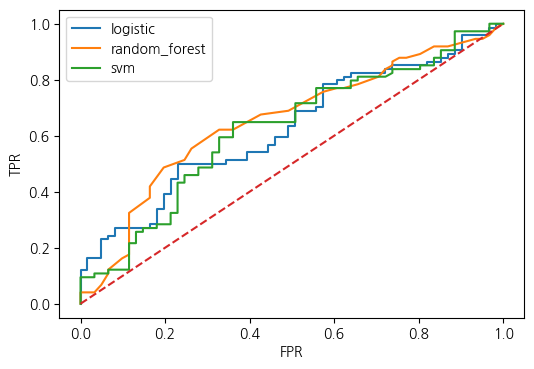

           model  accuracy  f1_weighted   ROC_AUC
0       logistic  0.585185     0.579794  0.625831
1  random_forest  0.607407     0.601535  0.653744
2            svm  0.570370     0.536527  0.623505
logistic [[28 33]
 [23 51]]
random_forest [[29 32]
 [21 53]]
svm [[17 44]
 [14 60]]


In [3]:
set_question('1-2')
credit_alg={'logistic':LogisticRegression(max_iter=1000),'random_forest':RandomForestClassifier(n_estimators=50,random_state=1234),'svm':SVC(probability=True,random_state=1234)}
credit_scores,credit_models,train,test=classify(credit,'churn',['gender','age','credit_grade','income'],OUT,seed=2022,algorithms=credit_alg)
from sklearn.metrics import confusion_matrix
for name,model in credit_models.items():print(name,confusion_matrix(credit.churn.iloc[test],model.predict(credit[['gender','age','credit_grade','income']].iloc[test])))

### 1-3

앞의 세 모형 확률을 결합해 이탈을 예측하고 result.csv를 저장하시오. 클래스 순서·동일 평가 구간을 검증하고 확률 결합의 한계를 설명하시오.

**판단 및 풀이 근거**

확률 평균은 클래스 열을 정렬하는 sklearn VotingClassifier에 맡깁니다. 상관된 오류·확률 보정·test 선정 편향을 설명합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [4]:
set_question('1-3')
from sklearn.ensemble import VotingClassifier
X=credit[['gender','age','credit_grade','income']];y=credit.churn
vote=VotingClassifier([(name,tabular_pipeline(X,est)) for name,est in credit_alg.items()],voting='soft')
vote.fit(X.iloc[train],y.iloc[train]);pred=vote.predict(X.iloc[test])
print('voting accuracy:',accuracy_score(y.iloc[test],pred));pd.DataFrame({'row_id':test,'credit':pred}).to_csv(OUT/'result.csv',index=False)

voting accuracy: 0.6074074074074074


## 2. 분기 교통 지표 예측

20년간 분기 관측 80개로 다음 16분기를 예측하려 한다. 1년은 4분기이며 앞 64개를 학습·진단·선택에만 사용한다.

자료: traffic_quarterly.csv

### 2-1

시간 성분을 분리하고 원자료와 4분기 차분 후의 수준 안정성을 평가하시오. 선택한 검정의 가설·통계량·p-value·기각 여부와 판단 한계를 제시하시오.

**판단 및 풀이 근거**

분기 자료를 4계절로 보고 ADF 검정의 H0(단위근 존재)를 원자료·계절 차분에서 평가한다. 분포의 정규성 검정과는 목적이 다르다.

**계산·해석 상세**

ADF 귀무가설은 단위근입니다. 정규성의 검정이 아니며 이분산은 시간별 분산 변화, 자기상관은 잔차 간 상관입니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

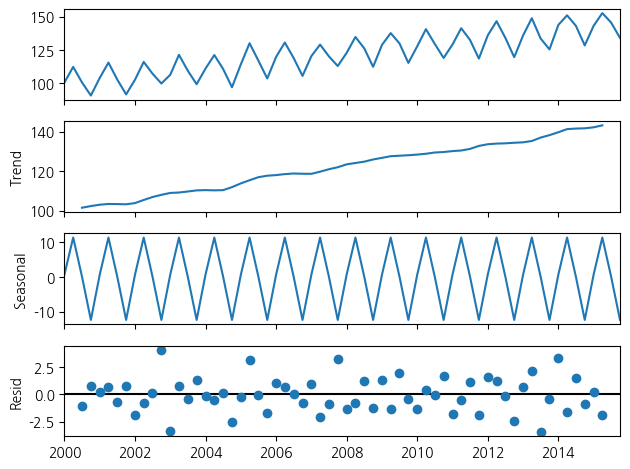

{'ADF_raw': np.float64(0.9632159275003446), 'ADF_seasonal_difference': np.float64(0.31763902536347366)}
{
  "question": "2-1",
  "method": "ADF: 분기 원자료",
  "H0": "단위근이 존재한다",
  "H1": "단위근이 없다",
  "statistic": 0.059923335176190175,
  "p_value": 0.9632159275003446,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "상수항 포함·AIC 시차 선택. 기각이 모든 형태의 정상성 또는 정규성을 입증하지 않는다.",
  "conclusion": "귀무가설을 기각하지 못한다. 분기 원자료에 단위근이 없다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다."
}
{
  "question": "2-1",
  "method": "ADF: 4분기 차분",
  "H0": "단위근이 존재한다",
  "H1": "단위근이 없다",
  "statistic": -1.9309612588022202,
  "p_value": 0.31763902536347366,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "상수항 포함·AIC 시차 선택. 기각이 모든 형태의 정상성 또는 정규성을 입증하지 않는다.",
  "conclusion": "귀무가설을 기각하지 못한다. 4분기 차분에 단위근이 없다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다."
}


In [5]:
set_question('2-1')
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
quarter=load('traffic_quarterly.csv');train_q=quarter.value.iloc[:64]
seasonal_decompose(pd.Series(train_q.to_numpy(),index=pd.to_datetime(quarter.date.iloc[:64])),period=4).plot();plt.show()
print({'ADF_raw':adfuller(train_q)[1],'ADF_seasonal_difference':adfuller(train_q.diff(4).dropna())[1]})

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
report_adf(train_q,'분기 원자료')
report_adf(train_q.diff(4).dropna(),'4분기 차분')

### 2-2

학습 자료를 추세·계절·잔차로 분리하고 평균·분산의 시간 변화를 살피시오. 분포의 정규성·정상성·이분산·자기상관을 구분하여 설명하시오.

**판단 및 풀이 근거**

후기의 개념 혼용을 교정합니다. 합성 예제와 실제 데이터의 분기 시간 격자를 확인해야 합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

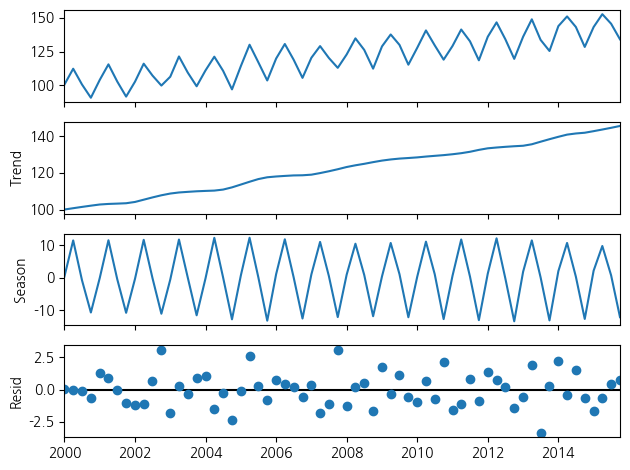

          mean        std
59  141.643696   9.473943
60  141.474827   9.427067
61  141.890891  10.007814
62  142.489484  10.184499
63  143.893122   7.686821
정규성은 분포, 정상성은 시간 불변성, 이분산은 분산 변화, 자기상관은 시차 의존성입니다.


In [6]:
set_question('2-2')
from statsmodels.tsa.seasonal import STL
STL(pd.Series(train_q.to_numpy(),index=pd.to_datetime(quarter.date.iloc[:64])),period=4).fit().plot();plt.show()
print(train_q.rolling(4).agg(['mean','std']).tail());print('정규성은 분포, 정상성은 시간 불변성, 이분산은 분산 변화, 자기상관은 시차 의존성입니다.')

### 2-3

분기 계절 구조를 반영한 모형 후보를 최소 3개 설정하고 학습 AIC로 선정하시오. 예측식 구조와 계절 주기 선정 근거를 설명하시오.

**판단 및 풀이 근거**

비계절 차수 3개와 분기 계절항 period=4를 비교합니다. 수렴·유한 AIC 조건을 만족하는 후보만 선택합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

       order         AIC  converged
0  (1, 0, 0)  361.601888       True
1  (1, 1, 0)  346.001204       True
2  (0, 1, 1)  330.261675       True
{'order': (0, 1, 1), 'RMSE': 3.0285464223639105, 'MAE': 2.6407259669961807, 'ADF_train_p': 0.9632159275003446}


/tmp/adp-update-py312/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:997: UserWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  warn('Non-stationary starting seasonal autoregressive'


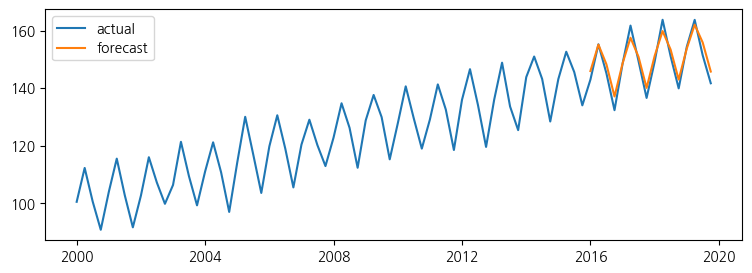

In [7]:
set_question('2-3')
quarter_model,quarter_metrics=seasonal_forecast(quarter,OUT,period=4)

### 2-4

선택 모형 잔차의 시차 의존성과 정규성을 평가하시오. 진단별 가설·통계량·p-value·기각 여부와 실제 잡음에 대한 해석의 한계를 제시하시오.

**판단 및 풀이 근거**

잔차의 정규성과 시차 무상관을 별도 가설로 평가하고, 선택한 비계절·계절 AR/MA 차수를 Ljung-Box 자유도에서 차감한다.

**계산·해석 상세**

잔차 자기상관과 이분산을 구분합니다. 모형 적합 잔차를 실제 잡음과 동일시하지 않습니다. 보류 오차는 후보 선택에 사용하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

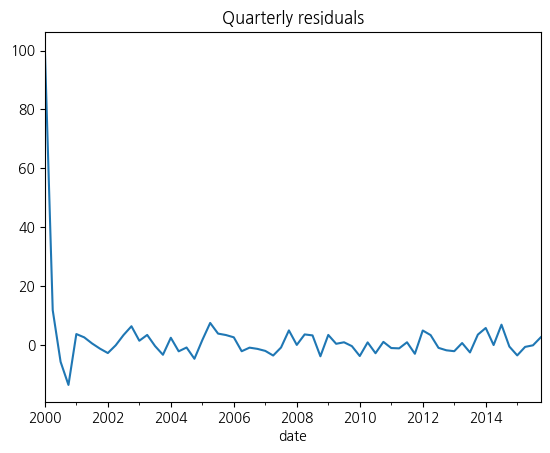

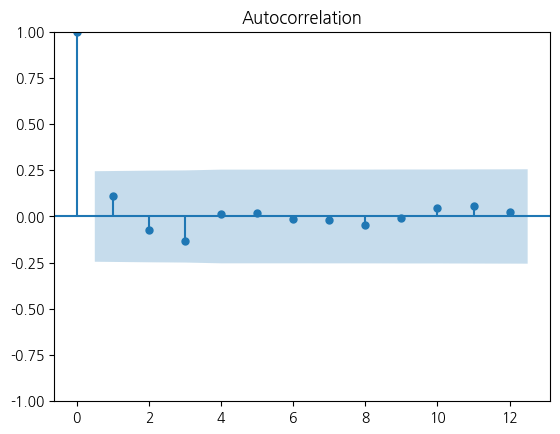

    lb_stat  lb_pvalue
4  2.425512   0.658022
8  2.645172   0.954617
ShapiroResult(statistic=np.float64(0.3278756452628959), pvalue=np.float64(1.4282997421988464e-15))
{
  "question": "2-4",
  "method": "Shapiro-Wilk: 분기 예측 모형 잔차",
  "H0": "잔차의 주변 분포가 정규이다",
  "H1": "잔차의 주변 분포가 정규가 아니다",
  "statistic": 0.3278756452628959,
  "p_value": 1.4282997421988464e-15,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "적합 잔차의 진단용 p값이며 독립 표본 검정과 같은 확증 해석에 주의한다.",
  "conclusion": "귀무가설을 기각한다. 분기 예측 모형 잔차가 정규 분포에서 벗어난다는 통계적 근거가 있다."
}
{
  "question": "2-4",
  "method": "Ljung-Box: 분기 예측 모형 잔차, lag=4",
  "H0": "lag 1~4의 자기상관이 모두 0이다",
  "H1": "해당 시차 중 하나 이상 자기상관이 0이 아니다",
  "statistic": 2.425511590753907,
  "p_value": 0.29737664002231295,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "적합한 AR·MA 계수 수를 자유도에서 차감한다. 정규성·등분산 검정과 구분한다.",
  "conclusion": "귀무가설을 기각하지 못한다. 분기 예측 모형 잔차에 잔여 시차 의존성이 있다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다.",
  "df": 2
}
{
  "question": "2-4",
  "method": "Ljung-B

In [8]:
set_question('2-4')
pd.Series(quarter_model.resid).plot();plt.title('Quarterly residuals');plt.show()
sm.graphics.tsa.plot_acf(quarter_model.resid,lags=12);plt.show()
print(sm.stats.acorr_ljungbox(quarter_model.resid,lags=[4,8],return_df=True));print(stats.shapiro(quarter_model.resid))

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
_order=quarter_model.model.order;_seasonal=quarter_model.model.seasonal_order
_model_df=_order[0]+_order[2]+_seasonal[0]+_seasonal[2]
report_residuals(quarter_model.resid,'분기 예측 모형 잔차',[4,8],_model_df)